# 이커머스 상품·고객 분석 리포트

원본 탐색 → 전처리 전후 비교 → NumPy 이미지·텍스트 피처 → 통계·IQR → RFM 세분화 → 민감도·비즈니스 제안의 전체 흐름입니다.

**거래와 이미지는 합성 데이터입니다.** 고객군은 가정에 따른 학습용 분류이며 실제 고객 행동이나 마케팅 효과를 입증하지 않습니다. 원본 탐색(1~9절)과 정제 후 분석(10절 이후)의 분모를 구분합니다.

커널은 프로젝트 `.venv`를 선택하고 위에서부터 실행하세요.

In [1]:
from pathlib import Path
import io
import pandas as pd
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dataset/raw/csv/ecommerce_retail_transactions_raw.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('프로젝트 루트 또는 하위 폴더에서 실행하세요.')
CSV_PATH = ROOT / 'dataset/raw/csv/ecommerce_retail_transactions_raw.csv'
MAPPING_PATH = ROOT / 'dataset/raw/images/image_mapping.csv'
# ID는 문자열로 보존하고, 모든 원본 값을 문자열로 읽어 형식 오류도 살펴봅니다.
raw = pd.read_csv(CSV_PATH, dtype='string')
if raw.empty:
    raise ValueError('분석할 거래 행이 없습니다.')
# 공백만 있는 값도 결측치로 보는 탐색용 복사본입니다. 원본 raw는 유지합니다.
df = raw.apply(lambda col: col.str.strip()).replace('', pd.NA)
def explain(text):
    display(Markdown('**결과 해석:** ' + text))
print('Pandas:', pd.__version__)
print('데이터:', CSV_PATH.relative_to(ROOT))

Pandas: 3.1.1
데이터: dataset/raw/csv/ecommerce_retail_transactions_raw.csv


## 1. 데이터 규모와 첫 행 확인
`shape`는 행·컬럼 수, `head()`는 첫 5개 거래를 보여줍니다. 여기서 전체 행 수는 고객 수나 고유 주문 수와 다릅니다.
자료형은 원본 형식 점검을 위해 우선 모두 문자열로 보존했습니다.

In [2]:
n_rows, n_cols = df.shape
display(pd.DataFrame({'항목': ['데이터 행 수', '컬럼 수'], '값': [n_rows, n_cols]}))
display(raw.head())
explain(f'전체 {n_rows:,}행, {n_cols}개 컬럼입니다. '
        f'미션의 규모 조건(1,000행 이상·8컬럼 이상)은 {"충족" if n_rows >= 1000 and n_cols >= 8 else "미충족"}합니다. '
        '다만 규모 충족만으로 고객 식별자와 날짜의 품질까지 보장되지는 않으므로 아래 검사가 필요합니다.')

,항목,값
0,데이터 행 수,12180
1,컬럼 수,13


,Order_ID,Customer_ID,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price_USD,Discount_Percent,Payment_Method,Shipping_City,Country,Order_Status,Customer_Rating
0,ORD011416,CUST00003,2026-04-03,Books,Self-Help Book,3,9.16,5.0,Net Banking,London,UK,Delivered,5.0
1,ORD000974,CUST00269,10-15-2024,Books,Fiction Novel,1,34.24,5.0,NetBanking,Toronto,CA,Shipped,<NA>
2,ORD000617,CUST02075,17 Jun 2024,Home & Kitchen,Vacuum Cleaner,2,111.95,15.0,DEBIT CARD,Brisbane,Australia,Shipped,<NA>
3,ORD006437,CUST02109,16/10/2025,Beauty,Hair Dryer,1,31.84,0.0,Cash on Delivery,Birmingham,U.K.,Delivered,3.0
4,ORD000740,CUST00349,06 Apr 2026,Home & Kitchen,Non-Stick Pan,2,72.0,<NA>,Credit_Card,Montreal,CA,Delivered,<NA>


**결과 해석:** 전체 12,180행, 13개 컬럼입니다. 미션의 규모 조건(1,000행 이상·8컬럼 이상)은 충족합니다. 다만 규모 충족만으로 고객 식별자와 날짜의 품질까지 보장되지는 않으므로 아래 검사가 필요합니다.

## 2. 자료형과 기초 통계
`info()`로 컬럼별 값의 존재 여부를 확인합니다. 이어서 수량·단가·할인율·평점을 **탐색용으로만 숫자로 변환**한 뒤 `describe()`로 분포를 봅니다.
변환 실패는 결측으로 표시하고 별도로 집계합니다. `std`는 표본 표준편차, 25%·50%·75%는 사분위수이며 50%는 중앙값입니다.

In [3]:
buffer = io.StringIO()
df.info(buf=buffer)
print(buffer.getvalue())
numeric_cols = ['Quantity', 'Unit_Price_USD', 'Discount_Percent', 'Customer_Rating']
numeric = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
conversion_failures = (df[numeric_cols].notna() & numeric.isna()).sum()
display(conversion_failures.rename('숫자 변환 실패 수').to_frame())
display(numeric.describe())
p = numeric['Unit_Price_USD']
explain(f'단가의 평균은 {p.mean():,.2f} USD, 중앙값은 {p.median():,.2f} USD, '
        f'표준편차는 {p.std():,.2f} USD입니다. '
        '평균과 중앙값의 차이 및 큰 최댓값은 고가 상품이나 입력 오류의 영향을 살펴볼 단서이며, 이 통계만으로 이상치 삭제를 결정하지 않습니다.')

<class 'pandas.DataFrame'>
RangeIndex: 12180 entries, 0 to 12179
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Order_ID          12180 non-null  string
 1   Customer_ID       12180 non-null  string
 2   Order_Date        12180 non-null  string
 3   Product_Category  12180 non-null  string
 4   Product_Name      12180 non-null  string
 5   Quantity          12180 non-null  string
 6   Unit_Price_USD    12180 non-null  string
 7   Discount_Percent  11445 non-null  string
 8   Payment_Method    12180 non-null  string
 9   Shipping_City     11678 non-null  string
 10  Country           12180 non-null  string
 11  Order_Status      12180 non-null  string
 12  Customer_Rating   6030 non-null   string
dtypes: string(13)
memory usage: 1.2 MB



,숫자 변환 실패 수
Quantity,0
Unit_Price_USD,0
Discount_Percent,0
Customer_Rating,0


,Quantity,Unit_Price_USD,Discount_Percent,Customer_Rating
count,12180.0,12180.0,11445.0,6030.0
mean,2.019458,61.55069,7.299257,3.896186
std,1.234956,52.53839,7.120143,1.113482
min,-1.0,3.01,0.0,1.0
25%,1.0,22.02,0.0,3.0
50%,2.0,42.765,5.0,4.0
75%,3.0,87.7125,10.0,5.0
max,5.0,249.84,25.0,5.0


**결과 해석:** 단가의 평균은 61.55 USD, 중앙값은 42.77 USD, 표준편차는 52.54 USD입니다. 평균과 중앙값의 차이 및 큰 최댓값은 고가 상품이나 입력 오류의 영향을 살펴볼 단서이며, 이 통계만으로 이상치 삭제를 결정하지 않습니다.

## 3. 결측치 확인
결측 개수와 전체 행 대비 비율을 함께 봅니다. 원래 비어 있던 값과 앞뒤 공백을 정리한 뒤 발견한 결측을 구분합니다.
평점 누락은 미평가, 할인율 누락은 미기록일 수 있으므로 의미를 확인하기 전에는 0으로 채우지 않습니다.

In [4]:
missing = pd.DataFrame({
    '원본 결측 수': raw.isna().sum(),
    '공백 포함 결측 수': df.isna().sum(),
    '결측 비율(%)': df.isna().mean().mul(100).round(2),
}).sort_values('공백 포함 결측 수', ascending=False)
display(missing)
top = missing.iloc[0]
if top['공백 포함 결측 수'] == 0:
    explain('전체 컬럼의 결측치는 0건입니다. 다음으로 형식 오류와 중복을 확인합니다.')
else:
    explain(f'결측이 가장 많은 컬럼은 {missing.index[0]}이며 {int(top["공백 포함 결측 수"]):,}건 '
            f'({top["결측 비율(%)"]:.2f}%)입니다. '
            '컬럼의 의미와 주문 상태에 따른 누락 패턴을 확인한 뒤 대치 여부를 결정해야 합니다.')
display(pd.crosstab(df['Order_Status'].fillna('(상태 누락)'),
                    df['Customer_Rating'].isna(), colnames=['평점 결측 여부']))

,원본 결측 수,공백 포함 결측 수,결측 비율(%)
Customer_Rating,6150,6150,50.49
Discount_Percent,735,735,6.03
Shipping_City,502,502,4.12
Order_ID,0,0,0.00
Customer_ID,0,0,0.00
Order_Date,0,0,0.00
Product_Category,0,0,0.00
Product_Name,0,0,0.00
Quantity,0,0,0.00
Unit_Price_USD,0,0,0.00


**결과 해석:** 결측이 가장 많은 컬럼은 Customer_Rating이며 6,150건 (50.49%)입니다. 컬럼의 의미와 주문 상태에 따른 누락 패턴을 확인한 뒤 대치 여부를 결정해야 합니다.

평점 결측 여부,False,True
Order_Status,,
Cancelled,0,1207
Delivered,6030,643
Pending,0,1416
Returned,0,1036
Shipped,0,1848


## 4. 중복과 식별자 점검
전체 컬럼이 같은 중복 행과 주문 번호만 같은 행은 다릅니다. `duplicated()` 기본값은 첫 행을 제외한 추가 중복 수입니다.
주문 번호가 반복되어도 여러 상품을 포함하는 주문일 수 있으므로 바로 삭제하지 않습니다.

In [5]:
exact_duplicates = int(raw.duplicated().sum())
normalized_duplicates = int(df.duplicated().sum())
order_counts = df['Order_ID'].value_counts()
repeated_order_ids = order_counts[order_counts > 1]
deduplicated = df.drop_duplicates()
remaining_counts = deduplicated['Order_ID'].value_counts()
remaining_repeated_ids = int(remaining_counts.gt(1).sum())
conflicting_customers = int(df.groupby('Order_ID')['Customer_ID'].nunique().gt(1).sum())
display(pd.Series({
    '원본 완전 중복 추가 행': exact_duplicates,
    '공백 정리 후 완전 중복 추가 행': normalized_duplicates,
    '고유 주문 ID(결측 제외)': df['Order_ID'].nunique(),
    '2행 이상 등장한 주문 ID 수': len(repeated_order_ids),
    '주문 ID 결측 행': df['Order_ID'].isna().sum(),
    '완전 중복 제거 후에도 반복되는 주문 ID 수': remaining_repeated_ids,
    '고객이 둘 이상인 주문 ID 수': conflicting_customers,
    '고객 ID 결측 행': df['Customer_ID'].isna().sum(),
}, name='건수').to_frame())
example_ids = repeated_order_ids.index[:5]
display(df[df['Order_ID'].isin(example_ids)].sort_values('Order_ID'))
explain(f'원본 완전 중복은 첫 행을 제외하고 {exact_duplicates:,}행이며, '
        f'반복 등장한 주문 ID는 {len(repeated_order_ids):,}개입니다. '
        f'공백 정리 후 완전 중복을 제외하면 반복 주문 ID는 {remaining_repeated_ids:,}개, 고객 충돌 주문 ID는 {conflicting_customers:,}개입니다. '
        'RFM 구매 횟수는 행 수 대신 고유 주문 수를 기준으로 계산하고, 반복 ID의 원인을 먼저 확인해야 합니다.')

,건수
원본 완전 중복 추가 행,180
공백 정리 후 완전 중복 추가 행,180
고유 주문 ID(결측 제외),12000
2행 이상 등장한 주문 ID 수,180
주문 ID 결측 행,0
완전 중복 제거 후에도 반복되는 주문 ID 수,0
고객이 둘 이상인 주문 ID 수,0
고객 ID 결측 행,0


,Order_ID,Customer_ID,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price_USD,Discount_Percent,Payment_Method,Shipping_City,Country,Order_Status,Customer_Rating
108,ORD000283,CUST02279,04 May 2026,Beauty,Face Moisturizer,1,9.4,<NA>,UPI,Manchester,uk,Delivered,4.0
881,ORD000283,CUST02279,04 May 2026,Beauty,Face Moisturizer,1,9.4,<NA>,UPI,Manchester,uk,Delivered,4.0
41,ORD003676,CUST00639,06 Jan 2025,Grocery,Almonds 500g,1,11.7,5.0,UPI,Abu Dhabi,U.A.E,Delivered,5.0
2040,ORD003676,CUST00639,06 Jan 2025,Grocery,Almonds 500g,1,11.7,5.0,UPI,Abu Dhabi,U.A.E,Delivered,5.0
106,ORD005308,CUST02026,26/08/2024,Grocery,Basmati Rice 5kg,3,20.41,10.0,Credit_Card,Hyderabad,india,Delivered,3.0
987,ORD005308,CUST02026,26/08/2024,Grocery,Basmati Rice 5kg,3,20.41,10.0,Credit_Card,Hyderabad,india,Delivered,3.0
79,ORD005394,CUST00342,12 Nov 2024,Grocery,Green Tea Pack,2,4.34,10.0,DEBIT CARD,Montreal,canada,Delivered,4.0
8797,ORD005394,CUST00342,12 Nov 2024,Grocery,Green Tea Pack,2,4.34,10.0,DEBIT CARD,Montreal,canada,Delivered,4.0
50,ORD007171,CUST00040,01-14-2025,Electronics,Webcam,3,189.65,0.0,credit card,Toronto,CA,Delivered,4.0
6910,ORD007171,CUST00040,01-14-2025,Electronics,Webcam,3,189.65,0.0,credit card,Toronto,CA,Delivered,4.0


**결과 해석:** 원본 완전 중복은 첫 행을 제외하고 180행이며, 반복 등장한 주문 ID는 180개입니다. 공백 정리 후 완전 중복을 제외하면 반복 주문 ID는 0개, 고객 충돌 주문 ID는 0개입니다. RFM 구매 횟수는 행 수 대신 고유 주문 수를 기준으로 계산하고, 반복 ID의 원인을 먼저 확인해야 합니다.

## 5. 고객·상품·카테고리와 표기 차이
고객별 고유 주문 수는 향후 RFM의 Frequency를 계산할 수 있는지 확인하는 기초 지표입니다. 아직 취소·반품을 제외하지 않은 원본 기준입니다.
상품은 모델 ID가 없으므로 우선 `Product_Name`을 연결 키로 사용합니다. 같은 이름이 실제 동일 모델임을 보장하지는 않습니다.

In [6]:
customer_orders = df.dropna(subset=['Customer_ID', 'Order_ID']).groupby('Customer_ID')['Order_ID'].nunique()
repeat_customers = int(customer_orders.ge(2).sum())
display(pd.Series({
    '고유 고객 수': df['Customer_ID'].nunique(),
    '고유 상품명 수': df['Product_Name'].nunique(),
    '고유 카테고리 수': df['Product_Category'].nunique(),
    '고유 주문이 2개 이상인 고객 수': repeat_customers,
}, name='개수').to_frame())
display(df.groupby('Product_Category', dropna=False).agg(
    거래_행수=('Order_ID', 'size'), 상품명_수=('Product_Name', 'nunique')))
display(df.groupby(['Product_Category', 'Product_Name'], dropna=False).size().rename('거래 행 수').reset_index())
for col in ['Country', 'Payment_Method', 'Order_Status']:
    print(f'\n{col} 원본 표기별 빈도')
    display(df[col].value_counts(dropna=False).rename('행 수').to_frame())
explain(f'고유 고객 {df["Customer_ID"].nunique():,}명 중 고유 주문이 2개 이상인 고객은 '
        f'{repeat_customers:,}명입니다. 취소·반품 포함 수치이므로 실제 반복 구매 고객 수는 분석 대상 상태를 정한 뒤 다시 계산해야 합니다.')

,개수
고유 고객 수,3374
고유 상품명 수,46
고유 카테고리 수,8
고유 주문이 2개 이상인 고객 수,2985


,거래_행수,상품명_수
Product_Category,,
Beauty,1510,6
Books,1552,4
Electronics,1507,8
Fashion,1539,8
Grocery,1491,4
Home & Kitchen,1568,7
Sports,1456,5
Toys,1557,4


,Product_Category,Product_Name,거래 행 수
0,Beauty,Face Moisturizer,227
1,Beauty,Hair Dryer,244
2,Beauty,Lipstick,258
3,Beauty,Perfume,281
4,Beauty,Shampoo,259
5,Beauty,Sunscreen SPF50,241
6,Books,Cookbook,396
7,Books,Fiction Novel,405
8,Books,Kids Storybook,381
9,Books,Self-Help Book,370



Country 원본 표기별 빈도


,행 수
Country,
UAE,609
australia,599
DE,596
Germany,592
IN,588
U.A.E,588
germany,587
Australia,586
india,584



Payment_Method 원본 표기별 빈도


,행 수
Payment_Method,
paypal,709
net banking,708
PayPal,695
UPI,692
Net Banking,690
DEBIT CARD,680
NetBanking,658
U.P.I,651
Pay Pal,649



Order_Status 원본 표기별 빈도


,행 수
Order_Status,
Delivered,6673
Shipped,1848
Pending,1416
Cancelled,1207
Returned,1036


**결과 해석:** 고유 고객 3,374명 중 고유 주문이 2개 이상인 고객은 2,985명입니다. 취소·반품 포함 수치이므로 실제 반복 구매 고객 수는 분석 대상 상태를 정한 뒤 다시 계산해야 합니다.

## 6. 날짜 형식과 거래 기간
혼합 형식에 일괄 자동 추론을 적용하면 월·일이 뒤바뀔 수 있습니다. 아래는 명시적인 형식 목록으로 파싱합니다.

- 연도가 앞인 날짜와 영문 월 날짜는 명시된 형식으로 변환합니다.
- 연도가 뒤인 숫자 날짜는 월/일과 일/월을 모두 시도합니다. 둘 다 유효하지만 서로 다르면 **모호한 날짜**로 표시합니다.
- 확정 기간에서는 모호한 날짜를 제외합니다. 참고용으로만 `MM-DD-YYYY`, `DD/MM/YYYY`라는 표기 가정을 적용한 기간도 보여줍니다. 출처 확인 전 이 가정을 확정하지 않습니다.
- 변환 실패 예시를 출력하며 원본 날짜를 덮어쓰지 않습니다.

구분자별로 일/월만 유효한 행과 월/일만 유효한 행을 따로 집계합니다. 가정과 불일치가 발견되면 참고용 기간도 재검토해야 합니다.

In [7]:
dates = df['Order_Date']
parsed = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
for fmt in ['%Y-%m-%d', '%Y/%m/%d', '%d %b %Y']:
    candidate = pd.to_datetime(dates, format=fmt, errors='coerce')
    parsed = parsed.fillna(candidate)
ambiguous = pd.Series(False, index=df.index)
assumed = parsed.copy()
format_checks = []
for sep, preferred in [('-', '%m-%d-%Y'), ('/', '%d/%m/%Y')]:
    mask = dates.str.fullmatch(r'\d{1,2}' + sep + r'\d{1,2}' + sep + r'\d{4}', na=False)
    day = pd.to_datetime(dates.where(mask), format=f'%d{sep}%m{sep}%Y', errors='coerce')
    month = pd.to_datetime(dates.where(mask), format=f'%m{sep}%d{sep}%Y', errors='coerce')
    conflict = mask & day.notna() & month.notna() & day.ne(month)
    preferred_candidate = pd.to_datetime(dates.where(mask), format=preferred, errors='coerce')
    format_checks.append({
        '구분자': sep, '가정 형식': preferred,
        '일/월만 유효': int((mask & day.notna() & month.isna()).sum()),
        '월/일만 유효': int((mask & month.notna() & day.isna()).sum()),
        '가정과 불일치(다른 해석만 유효)': int((mask & preferred_candidate.isna() & (day.notna() | month.notna())).sum()),
    })
    ambiguous |= conflict
    parsed = parsed.fillna(day.fillna(month).mask(conflict))
    assumed = assumed.fillna(pd.to_datetime(dates.where(mask), format=preferred, errors='coerce'))
# 한쪽 해석만 유효한 날짜는 참고용 시리즈에도 보존합니다.
assumed = assumed.fillna(parsed)
failed = dates.notna() & parsed.isna() & ~ambiguous
display(pd.DataFrame(format_checks))
display(pd.Series({
    '날짜 결측 행' : int(dates.isna().sum()),
    '모호한 날짜 행': int(ambiguous.sum()),
    '형식 오류 또는 변환 실패 행': int(failed.sum()),
    '모호하지 않은 변환 성공 행': int(parsed.notna().sum()),
}, name='행 수').rename(index={'날짜 결측 행':'날짜 결측 행'}).to_frame())
display(pd.DataFrame({'집계 기준': ['모호한 날짜 제외', '표기 가정 적용(미확정)'],
                      '최초 거래일': [parsed.min(), assumed.min()],
                      '최종 거래일': [parsed.max(), assumed.max()]}))
display(pd.DataFrame({'원본 날짜': dates[ambiguous | failed],
                      '판정': ambiguous[ambiguous | failed].map({True:'월·일 모호', False:'변환 실패'})}).head(15))
explain(f'모호한 날짜가 {int(ambiguous.sum()):,}행, 변환 실패가 {int(failed.sum()):,}행입니다. '
        f'모호하지 않은 {int(parsed.notna().sum()):,}행의 기간은 {parsed.min()}부터 {parsed.max()}까지입니다. '
        'RFM의 최근 구매일과 월별 매출은 날짜 해석에 민감하므로 출처에서 형식을 확인한 뒤 전체 기간과 기준일을 확정해야 합니다.')

,구분자,가정 형식,일/월만 유효,월/일만 유효,가정과 불일치(다른 해석만 유효)
0,-,%m-%d-%Y,0,1494,0
1,/,%d/%m/%Y,1464,0,0


,행 수
날짜 결측 행,0
모호한 날짜 행,1802
형식 오류 또는 변환 실패 행,0
모호하지 않은 변환 성공 행,10378


,집계 기준,최초 거래일,최종 거래일
0,모호한 날짜 제외,2024-01-01,2026-06-30
1,표기 가정 적용(미확정),2024-01-01,2026-06-30


,원본 날짜,판정
5,11-09-2024,월·일 모호
7,10/07/2024,월·일 모호
10,06-05-2024,월·일 모호
13,12-09-2024,월·일 모호
32,07/02/2024,월·일 모호
33,07-08-2025,월·일 모호
35,02/06/2025,월·일 모호
43,03/07/2025,월·일 모호
46,02-10-2024,월·일 모호
55,01-10-2025,월·일 모호


**결과 해석:** 모호한 날짜가 1,802행, 변환 실패가 0행입니다. 모호하지 않은 10,378행의 기간은 2024-01-01 00:00:00부터 2026-06-30 00:00:00까지입니다. RFM의 최근 구매일과 월별 매출은 날짜 해석에 민감하므로 출처에서 형식을 확인한 뒤 전체 기간과 기준일을 확정해야 합니다.

## 7. 주문 상태와 숫자 값의 유효성
취소·반품·배송 중·배송 완료가 섞여 있는지 확인합니다. 여기서는 매출을 확정하거나 상태별 행을 제거하지 않습니다.
수량·단가가 0 이하이거나 할인율·평점 범위를 벗어난 값은 오류 후보이며, 반품 표현 방식 등 출처 설명과 함께 판단합니다.

In [8]:
status = df['Order_Status'].value_counts(dropna=False).rename('행 수').to_frame()
status['비율(%)'] = (status['행 수'] / n_rows * 100).round(2)
display(status)
invalid_rules = {
    '수량 0 이하': numeric['Quantity'].le(0),
    '수량이 정수가 아님': numeric['Quantity'].notna() & numeric['Quantity'].mod(1).ne(0),
    '단가 0 이하': numeric['Unit_Price_USD'].le(0),
    '할인율 0~100 범위 밖': numeric['Discount_Percent'].lt(0) | numeric['Discount_Percent'].gt(100),
    '평점 1~5 범위 밖': numeric['Customer_Rating'].lt(1) | numeric['Customer_Rating'].gt(5),
}
display(pd.Series({k:int(v.sum()) for k,v in invalid_rules.items()}, name='후보 행 수').to_frame())
display(pd.crosstab(df['Order_Status'].fillna('(상태 누락)'),
                    invalid_rules['수량 0 이하'], colnames=['수량 0 이하 여부']))
explain(f'주문 상태는 결측을 제외하고 {df["Order_Status"].nunique()}종류입니다. '
        f'수량 0 이하 후보는 {int(invalid_rules["수량 0 이하"].sum()):,}행입니다. '
        '상태별 구매 인정 기준과 숫자 오류 처리 기준을 먼저 정해야 실제 매출과 RFM을 과대 계산하지 않습니다.')

,행 수,비율(%)
Order_Status,,
Delivered,6673,54.79
Shipped,1848,15.17
Pending,1416,11.63
Cancelled,1207,9.91
Returned,1036,8.51


,후보 행 수
수량 0 이하,192
수량이 정수가 아님,0
단가 0 이하,0
할인율 0~100 범위 밖,0
평점 1~5 범위 밖,0


수량 0 이하 여부,False,True
Order_Status,,
Cancelled,1189,18
Delivered,6563,110
Pending,1390,26
Returned,1017,19
Shipped,1829,19


**결과 해석:** 주문 상태는 결측을 제외하고 5종류입니다. 수량 0 이하 후보는 192행입니다. 상태별 구매 인정 기준과 숫자 오류 처리 기준을 먼저 정해야 실제 매출과 RFM을 과대 계산하지 않습니다.

## 8. 전체 상품과 이미지 연결 검사
이미지는 첫 100행에 나온 상품명을 기준으로 만든 합성 스케치입니다. 전체 CSV의 상품명과 비교하고 매핑 키 중복, 파일 부재, 경로 범위도 확인합니다.
같은 상품을 여러 번 거래해도 이미지 한 장을 공유합니다. 합성 스케치의 평균·표준편차는 실제 상품 외관이나 구매 원인을 나타내지 않습니다.

In [9]:
mapping = pd.read_csv(MAPPING_PATH, dtype='string')
mapping['image_path'] = mapping['image_path'].str.strip()
map_names = mapping['Product_Name'].str.strip()
if map_names.isna().any() or map_names.duplicated().any():
    raise ValueError('이미지 매핑의 상품명 누락 또는 중복을 먼저 해결하세요.')
def image_exists(value):
    if pd.isna(value):
        return False
    path = (ROOT / str(value)).resolve()
    return path.is_relative_to((ROOT / 'dataset/raw/images').resolve()) and path.is_file()
mapping['파일 존재'] = mapping['image_path'].map(image_exists)
mapping['Product_Name'] = map_names
available = set(mapping.loc[mapping['파일 존재'], 'Product_Name'])
products = set(df['Product_Name'].dropna())
missing_products = sorted(products - available)
extra_products = sorted(set(map_names.dropna()) - products)
unmatched = df['Product_Name'].isna() | ~df['Product_Name'].isin(available)
display(pd.Series({
    '전체 고유 상품명': len(products), '매핑 상품명': len(mapping),
    '파일이 없는 매핑': int((~mapping['파일 존재']).sum()),
    '이미지 미연결 고유 상품명': len(missing_products),
    '이미지 미연결 거래 행(상품명 결측 포함)': int(unmatched.sum()),
    'CSV에 없는 매핑 상품명': len(extra_products),
}, name='개수').to_frame())
display(pd.DataFrame({'이미지 추가 필요 상품명': missing_products}))
display(mapping.head())
explain(f'전체 상품명 {len(products)}개 중 이미지가 없는 상품명은 {len(missing_products)}개이며, '
        f'미연결 거래는 {int(unmatched.sum()):,}행({unmatched.mean()*100:.2f}%)입니다. '
        '누락이 있으면 확인 목록을 검토하고, 이미지 피처 연결은 12절에서 확인합니다.')

,개수
전체 고유 상품명,46
매핑 상품명,46
파일이 없는 매핑,0
이미지 미연결 고유 상품명,0
이미지 미연결 거래 행(상품명 결측 포함),0
CSV에 없는 매핑 상품명,0


,이미지 추가 필요 상품명


,Product_Name,image_path,image_source,파일 존재
0,Action Figure,dataset/raw/images/action_figure.png,AI-generated representative sketch,True
1,Air Fryer,dataset/raw/images/air_fryer.png,AI-generated representative sketch,True
2,Almonds 500g,dataset/raw/images/almonds_500g.png,AI-generated representative sketch,True
3,Backpack,dataset/raw/images/backpack.png,AI-generated representative sketch,True
4,Basmati Rice 5kg,dataset/raw/images/basmati_rice_5kg.png,AI-generated representative sketch,True


**결과 해석:** 전체 상품명 46개 중 이미지가 없는 상품명은 0개이며, 미연결 거래는 0행(0.00%)입니다. 누락이 있으면 확인 목록을 검토하고, 이미지 피처 연결은 12절에서 확인합니다.

## 9. 원본 탐색 요약

아래 표는 전처리 이전의 점검 결과입니다. 다음 절부터 정제된 거래로 분석합니다. 원본의 날짜 모호성 1,802행과 중복 제거 후 국가 가정 적용 1,777행의 분모는 다릅니다.

In [10]:
summary = pd.DataFrame([
    ['결측치', f'{int(df.isna().sum().sum()):,}개 셀', '그룹별 대치 대상과 미기록 유지 대상을 구분'],
    ['완전 중복', f'{exact_duplicates:,}개 추가 행', '생성 원인 확인 후 제거 여부 결정'],
    ['날짜 모호성', f'{int(ambiguous.sum()):,}행', '출처 형식 확인 후 파싱 규칙 확정'],
    ['날짜 변환 실패', f'{int(failed.sum()):,}행', '원본 표기 확인 및 실패 처리 기준 수립'],
    ['주문 상태', f'{df["Order_Status"].nunique()}종', 'RFM·매출에 포함할 상태 결정'],
    ['이미지 누락', f'{len(missing_products)}개 상품명 / {int(unmatched.sum()):,}행', '누락 품목·상품명 점검'],
], columns=['항목', '탐색 결과', '다음 작업'])
display(summary)
explain(f'총 {n_rows:,}행을 탐색했습니다. 전처리 기준은 문서에 기록했고 10절에서 구현 결과를 확인합니다. '
        '이번 결과는 원본 기준이므로 정제 후 고객 수와 거래 기간을 다시 확인해야 합니다.')

,항목,탐색 결과,다음 작업
0,결측치,"7,387개 셀",그룹별 대치 대상과 미기록 유지 대상을 구분
1,완전 중복,180개 추가 행,생성 원인 확인 후 제거 여부 결정
2,날짜 모호성,"1,802행",출처 형식 확인 후 파싱 규칙 확정
3,날짜 변환 실패,0행,원본 표기 확인 및 실패 처리 기준 수립
4,주문 상태,5종,RFM·매출에 포함할 상태 결정
5,이미지 누락,0개 상품명 / 0행,누락 품목·상품명 점검


**결과 해석:** 총 12,180행을 탐색했습니다. 전처리 기준은 문서에 기록했고 10절에서 구현 결과를 확인합니다. 이번 결과는 원본 기준이므로 정제 후 고객 수와 거래 기간을 다시 확인해야 합니다.

## 10. 전처리·전체 분석 실행과 전후 비교
`run_analysis()`는 원본을 보존하고 전처리, 피처 생성, 통계, RFM, 민감도 비교와 차트 저장을 수행합니다. 정상 실행 시 터미널 출력은 없습니다. 결과는 `dataset/processed/`와 `output/analysis/`에 저장합니다.

전후 표는 제거 전 12,180행과 중복 제거 후 12,000행 기준입니다. 평점 결측 감소분은 대치 결과가 아니라 중복 제거의 영향입니다.

In [11]:
import sys
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from src.reporting import run_analysis
from IPython.display import Image
report = run_analysis()
a = report['analyzer']
eligible = report['eligible']
rfm = report['rfm']
segments = report['segment']
summary = report['summary']
display(report['before_after'])
display(pd.Series(a.summary).drop('country_separator_date_patterns').to_frame('결과'))
explain(f'중복 {a.summary["duplicates_removed"]:,}행을 제거해 {len(a.df):,}행을 보존했습니다. '
        f'그중 유효 완료 구매 {len(eligible):,}행을 금액·RFM 공통 대상으로 사용합니다. '
        '확인 필요 거래와 분석 제외 거래는 동일한 개념이 아니므로 별도 집계합니다.')

,metric,raw_rows_basis,deduplicated_rows_basis
0,rows,12180,12000
1,missing_discount,735,0
2,missing_city,502,0
3,missing_rating,6150,6056


,결과
input_rows,12180
duplicates_removed,180
cleaned_rows,12000
review_items,1668
review_rows,1653
analysis_eligible_rows,5700
analysis_excluded_rows,6300
analysis_eligible_customers,2823
date_status_counts,"{'explicit': 7153, 'country_assumed': 1777, 'c..."
discount_fill_counts,"{'observed': 11278, 'product_median': 722}"


**결과 해석:** 중복 180행을 제거해 12,000행을 보존했습니다. 그중 유효 완료 구매 5,700행을 금액·RFM 공통 대상으로 사용합니다. 확인 필요 거래와 분석 제외 거래는 동일한 개념이 아니므로 별도 집계합니다.

## 11. 확인 필요 항목의 검토와 처리 결정
확인 목록은 행 삭제 명령이 아닙니다. 국가 규칙 충돌은 유효 날짜 후보를 남기고 날짜 분석에서 보류합니다. 수량 오류는 양수로 강제 변경하지 않습니다. 원본을 복구할 근거가 없으므로 미해결 상태를 유지합니다.

제공자 [Kaggle 데이터 페이지](https://www.kaggle.com/datasets/afaqkhan091/messy-e-commerce-sales-dataset-2026) 및 [메타데이터 API](https://www.kaggle.com/api/v1/datasets/view/afaqkhan091/messy-e-commerce-sales-dataset-2026)는 합성 데이터·CC0와 혼합 날짜 형식을 설명합니다. 국가별 형식을 따른다는 설명은 확인되지 않아 해당 규칙은 사용자 승인 가정으로 유지합니다.

In [12]:
display(a.review_required.groupby(['column','reason']).size().rename('항목 수').to_frame())
display(a.review_required.head(10))
display(pd.DataFrame(a.summary['country_separator_date_patterns']))
explain(f'확인 필요 거래 {a.summary["review_rows"]:,}행에 총 {a.summary["review_items"]:,}개 항목이 있습니다. '
        f'날짜 보류 {summary["dates_review_held"]:,}행을 임의 복원하지 않고, 후반부에서 같은 거래 집합의 해석 민감도를 비교합니다.')

,,항목 수
column,reason,
Order_Date,country_format_conflict,1482
Quantity,out_of_range,186


,source_csv_row,Order_ID,column,original_value,reason,country_normalized,candidate_mdy,candidate_dmy
0,3,ORD000974,Order_Date,10-15-2024,country_format_conflict,Canada,2024-10-15,NaT
1,10,ORD005427,Order_Date,19/08/2025,country_format_conflict,USA,NaT,2025-08-19
2,11,ORD002304,Order_Date,07-14-2025,country_format_conflict,Germany,2025-07-14,NaT
3,21,ORD011697,Order_Date,04-16-2026,country_format_conflict,Germany,2026-04-16,NaT
4,26,ORD005984,Order_Date,05-22-2025,country_format_conflict,UAE,2025-05-22,NaT
5,33,ORD007969,Order_Date,04-20-2026,country_format_conflict,Germany,2026-04-20,NaT
6,47,ORD004756,Order_Date,02-27-2025,country_format_conflict,Australia,2025-02-27,NaT
7,52,ORD007171,Order_Date,01-14-2025,country_format_conflict,Canada,2025-01-14,NaT
8,58,ORD002014,Order_Date,28/01/2025,country_format_conflict,USA,NaT,2025-01-28
9,60,ORD011962,Order_Date,01-23-2026,country_format_conflict,India,2026-01-23,NaT


,country,separator,interpretation,rows
0,Australia,-,both,126
1,Australia,-,mdy_only,199
2,Australia,/,both,135
3,Australia,/,dmy_only,191
4,Canada,-,both,140
5,Canada,-,mdy_only,193
6,Canada,/,both,141
7,Canada,/,dmy_only,194
8,Germany,-,both,149
9,Germany,-,mdy_only,207


**결과 해석:** 확인 필요 거래 1,653행에 총 1,668개 항목이 있습니다. 날짜 보류 1,482행을 임의 복원하지 않고, 후반부에서 같은 거래 집합의 해석 민감도를 비교합니다.

## 12. 멀티모달 피처 엔지니어링
상품명 길이와 단어 수를 Pandas 문자열 연산으로 계산합니다. 이미지는 Matplotlib의 허용된 `imread()`로 읽고, NumPy 인덱싱과 흰 패딩으로 종횡비를 유지한 64×64 RGB 배열로 정규화합니다. 픽셀 값은 0~1입니다.

파일 I/O·크기 정규화는 이미지별로 순회하지만, **평균·표준편차는 `np.stack()`한 `(N, 64, 64, 3)` 배열에 `mean(axis=(1,2,3))`, `std(axis=(1,2,3))`로 한 번에 계산**합니다. Pillow·OpenCV를 직접 사용하지 않습니다. Matplotlib 설치 과정의 내부 의존성과 분석 코드의 직접 사용은 구분합니다.

한 상품 이미지가 여러 거래에 반복 연결되므로 이미지 관련 거래 수준 상관관계를 독립적인 상품 5,700개의 증거로 해석하지 않습니다.

In [13]:
features = pd.read_csv(report['output_dir'] / 'image_features.csv')
display(features.head(10))
display(a.df[['product_name','product_name_length','product_word_count','image_mean','image_std']].head())
explain(f'고유 상품 {len(features)}개의 이미지 통계가 모든 {len(a.df):,}개 거래에 연결됐습니다. '
        f'이미지 평균 범위는 {features.image_mean.min():.4f}~{features.image_mean.max():.4f}입니다. '
        '이는 합성 선화의 흰 여백·윤곽선 차이를 나타내며 구매 원인을 뜻하지 않습니다.')

,product_name,image_path,image_mean,image_std
0,Action Figure,dataset/raw/images/action_figure.png,0.958899,0.178462
1,Air Fryer,dataset/raw/images/air_fryer.png,0.954654,0.194288
2,Almonds 500g,dataset/raw/images/almonds_500g.png,0.928578,0.228748
3,Backpack,dataset/raw/images/backpack.png,0.947922,0.203234
4,Basmati Rice 5kg,dataset/raw/images/basmati_rice_5kg.png,0.976770,0.136330
5,Blender,dataset/raw/images/blender.png,0.957120,0.190161
6,Bluetooth Speaker,dataset/raw/images/bluetooth_speaker.png,0.969483,0.162185
7,Building Blocks Set,dataset/raw/images/building_blocks_set.png,0.964047,0.172508
8,Ceramic Mug Set,dataset/raw/images/ceramic_mug_set.png,0.971880,0.151942
9,Cookbook,dataset/raw/images/cookbook.png,0.944920,0.213963


,product_name,product_name_length,product_word_count,image_mean,image_std
0,Self-Help Book,14,2,0.982193,0.115989
1,Fiction Novel,13,2,0.980090,0.127016
2,Vacuum Cleaner,14,2,0.957019,0.189978
3,Hair Dryer,10,2,0.978390,0.134130
4,Non-Stick Pan,13,2,0.980722,0.124783


**결과 해석:** 고유 상품 46개의 이미지 통계가 모든 12,000개 거래에 연결됐습니다. 이미지 평균 범위는 0.9286~0.9912입니다. 이는 합성 선화의 흰 여백·윤곽선 차이를 나타내며 구매 원인을 뜻하지 않습니다.

## 13. 기술 통계와 분포
유효 완료 구매 거래를 단위로 평균·중앙값·표준편차·사분위수를 계산합니다. 단가는 USD이며 같은 상품이라도 여러 거래에 등장합니다. 고액 관측값을 오류로 단정하지 않습니다.

,count,mean,std,min,25%,50%,75%,max
quantity,5700.0,2.071754,1.202855,1.0,1.0,2.0,3.0,5.0
unit_price_usd,5700.0,61.482835,52.605357,3.04,21.89,42.04,87.7625,249.75
discount_percent_filled,5700.0,7.219298,6.993415,0.0,0.0,5.0,10.0,25.0
amount_estimated_usd,5700.0,118.56174,137.235563,2.736,31.635,70.28,149.757375,1237.0
product_name_length,5700.0,12.265263,3.245441,6.0,10.0,13.0,14.0,19.0
image_mean,5700.0,0.965432,0.015045,0.928578,0.953878,0.967909,0.97839,0.991153
image_std,5700.0,0.162574,0.037989,0.079228,0.13413,0.1636,0.193735,0.228748


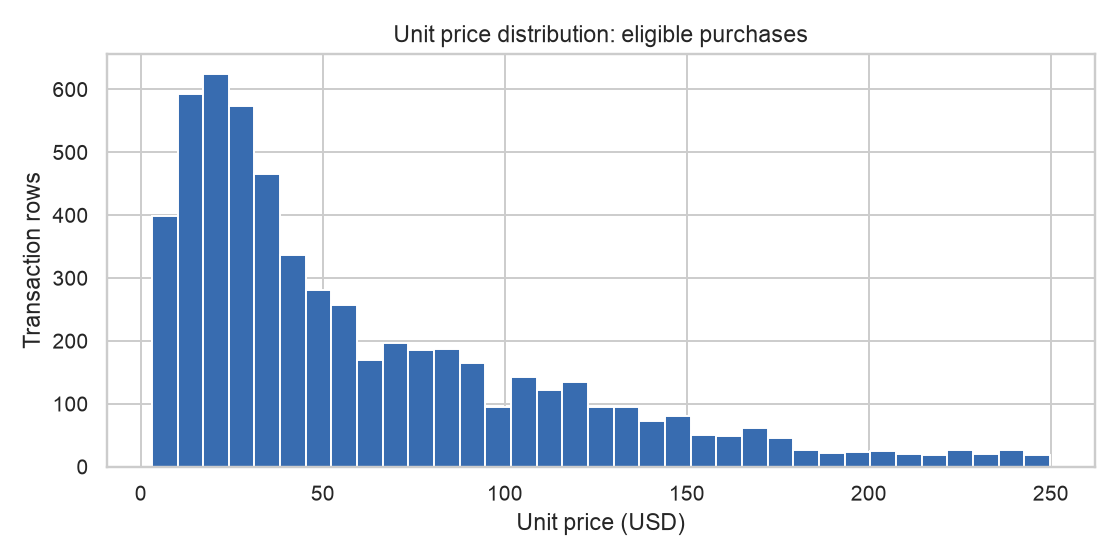

**결과 해석:** 유효 완료 구매 단가 평균은 61.48 USD, 중앙값은 42.04 USD, 표준편차는 52.61 USD이며, 사분위 범위는 21.89~87.76 USD입니다. 단가 분포와 중앙값을 함께 보고 고가 거래에 평균이 얼마나 영향을 받는지 확인해야 합니다.

In [14]:
display(report['stats'])
display(Image(filename=str(report['output_dir']/'figures/01_histogram.png')))
s = report['stats'].loc['unit_price_usd']
explain(f'유효 완료 구매 단가 평균은 {s["mean"]:.2f} USD, 중앙값은 {s["50%"]:.2f} USD, '
        f'표준편차는 {s["std"]:.2f} USD이며, 사분위 범위는 {s["25%"]:.2f}~{s["75%"]:.2f} USD입니다. '
        '단가 분포와 중앙값을 함께 보고 고가 거래에 평균이 얼마나 영향을 받는지 확인해야 합니다.')

## 14. 직접 구현한 IQR 탐지와 처리 전후 비교
IQR=Q3−Q1, 하한=Q1−1.5×IQR, 상한=Q3+1.5×IQR입니다. 탐지 메서드는 오류·무한대를 제외하고 임계값을 인자로 받습니다.

박스플롯은 유효 단가를 경계값으로 클리핑한 **EDA용 비교**입니다. 실제 매출·RFM 계산은 클리핑하지 않은 유효 거래를 유지합니다. 파생 금액을 그대로 둔 채 단가만 수정하는 불일치를 피하기 위해 비교용 시리즈만 만듭니다.

,source_csv_row,product_name,unit_price_usd
22,24,Gaming Mouse,193.68
36,38,Bluetooth Speaker,242.81
119,121,Gaming Mouse,227.77
134,136,Power Bank,236.11
297,299,Smartwatch,242.28
338,340,Laptop Stand,242.38
369,371,Power Bank,204.49
465,467,Smartwatch,213.67
500,502,Bluetooth Speaker,218.69
576,578,Webcam,209.31


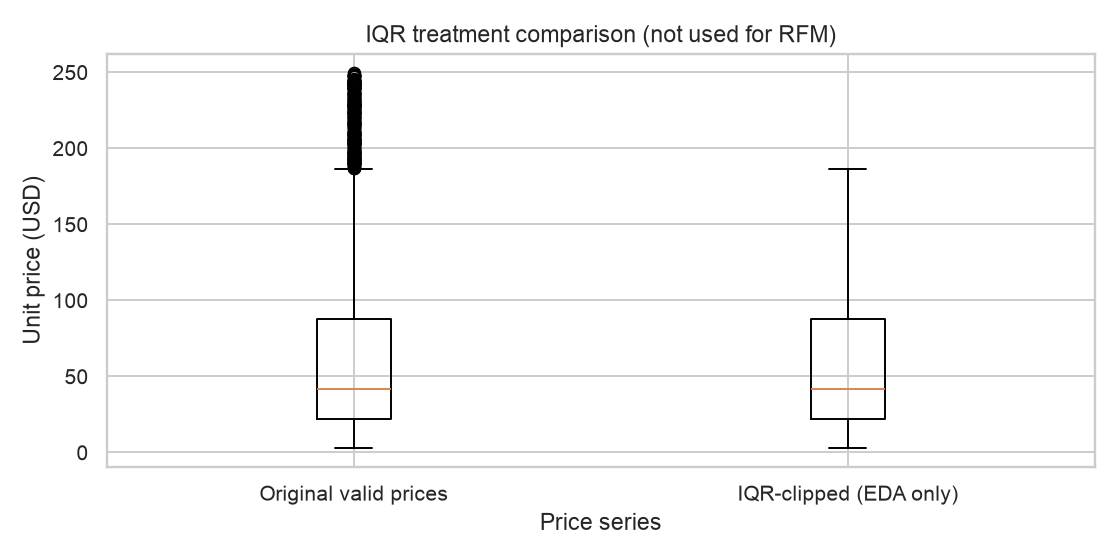

**결과 해석:** IQR 하한 -76.92, 상한 186.57 USD 기준으로 200행(3.51%)이 탐지됐습니다. 클리핑 시 평균은 61.48에서 60.38 USD로 변합니다. 정상 고액 구매일 수 있어 RFM에서는 자동 제거하지 않습니다.

In [15]:
outliers = a.detect_outliers('unit_price_usd', threshold=1.5, eligible_only=True)
display(outliers[['source_csv_row','product_name','unit_price_usd']].head(10))
display(Image(filename=str(report['output_dir']/'figures/02_boxplot.png')))
explain(f'IQR 하한 {summary["iqr_price_lower"]:.2f}, 상한 {summary["iqr_price_upper"]:.2f} USD 기준으로 '
        f'{len(outliers):,}행({len(outliers)/len(eligible)*100:.2f}%)이 탐지됐습니다. '
        f'클리핑 시 평균은 {summary["price_mean_before"]:.2f}에서 {summary["price_mean_clipped"]:.2f} USD로 변합니다. '
        '정상 고액 구매일 수 있어 RFM에서는 자동 제거하지 않습니다.')

## 15. 상관관계와 산점도
Pearson 상관계수는 선형 관계를 요약합니다. 금액이 단가×수량으로 계산되므로 이 변수들의 상관에는 산술적 구조가 포함됩니다. 상관관계는 인과관계가 아니며, 반복 거래와 합성 이미지의 한계도 고려합니다.

,quantity,unit_price_usd,discount_percent_filled,amount_estimated_usd,product_name_length,image_mean,image_std
quantity,1.000000,0.006985,-0.009443,0.503121,0.000427,0.024431,-0.020201
unit_price_usd,0.006985,1.000000,0.012137,0.749131,-0.077173,0.041447,-0.023749
discount_percent_filled,-0.009443,0.012137,1.000000,-0.062090,-0.018056,0.018244,-0.017641
amount_estimated_usd,0.503121,0.749131,-0.062090,1.000000,-0.059770,0.040826,-0.024203
product_name_length,0.000427,-0.077173,-0.018056,-0.059770,1.000000,-0.124462,0.141092
image_mean,0.024431,0.041447,0.018244,0.040826,-0.124462,1.000000,-0.979989
image_std,-0.020201,-0.023749,-0.017641,-0.024203,0.141092,-0.979989,1.000000


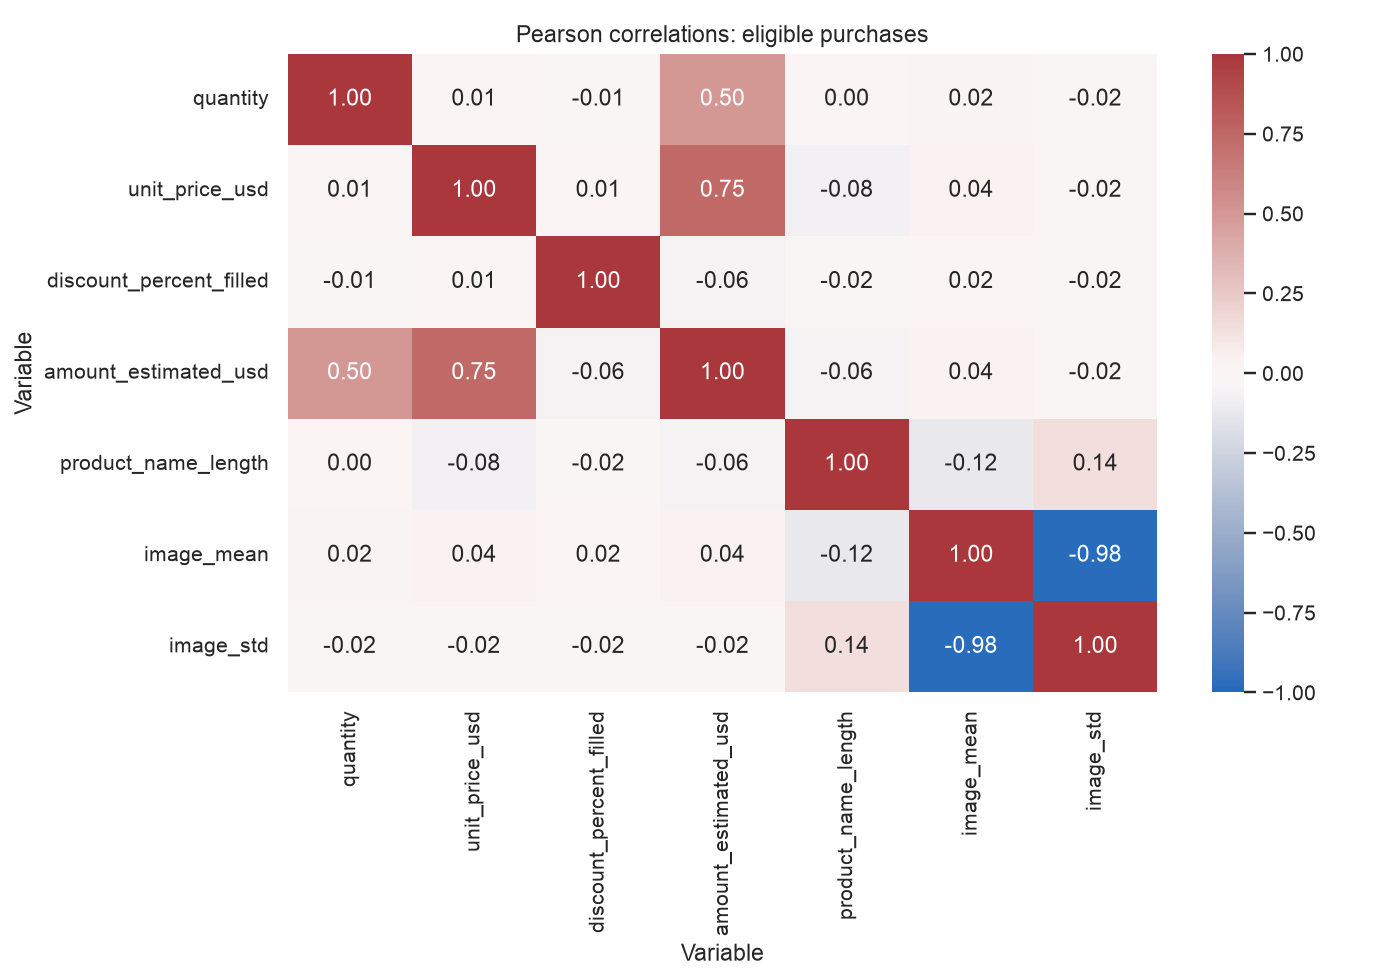

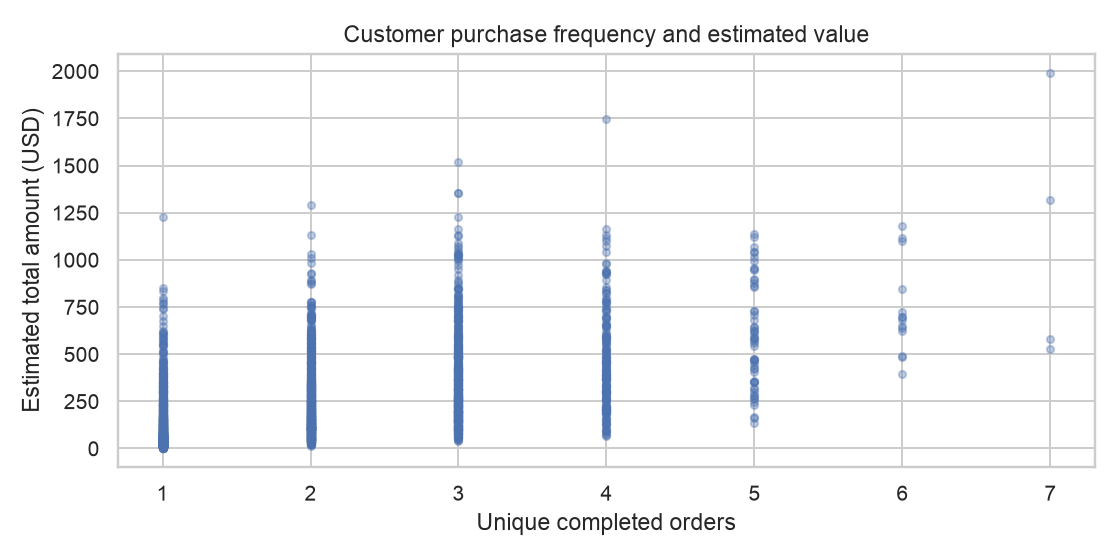

**결과 해석:** unit_price_usd와 amount_estimated_usd의 상관계수는 0.749입니다. 금액 산식에 포함된 변수이므로 관계가 보여도 가격 또는 수량의 독립적 인과 효과로 해석하지 않습니다.

**결과 해석:** quantity와 amount_estimated_usd의 상관계수는 0.503입니다. 금액 산식에 포함된 변수이므로 관계가 보여도 가격 또는 수량의 독립적 인과 효과로 해석하지 않습니다.

**결과 해석:** image_mean와 image_std의 상관계수는 -0.980입니다. 합성 스케치의 흰 여백과 선 비중에 따른 구조적 관계이며 상품 수요의 근거가 아닙니다.

In [16]:
display(report['corr'])
display(Image(filename=str(report['output_dir']/'figures/04_heatmap.png')))
display(Image(filename=str(report['output_dir']/'figures/05_scatter.png')))
for x,y in [('unit_price_usd','amount_estimated_usd'),('quantity','amount_estimated_usd'),('image_mean','image_std')]:
    value = report['corr'].loc[x,y]
    explain(f'{x}와 {y}의 상관계수는 {value:.3f}입니다. '
            + ('금액 산식에 포함된 변수이므로 관계가 보여도 가격 또는 수량의 독립적 인과 효과로 해석하지 않습니다.'
               if 'amount' in y else '합성 스케치의 흰 여백과 선 비중에 따른 구조적 관계이며 상품 수요의 근거가 아닙니다.'))

## 16. 월별 추세
0건인 중간 월도 0으로 채워 표시합니다. 금액은 완료 구매의 추정 할인 후 금액이며 모든 주문의 총매출이나 회계상 순매출이 아닙니다. 날짜 가정으로 거래가 다른 달로 이동할 수 있어 계절성·성장률을 확정하지 않습니다.

모호하지 않은 날짜의 최대일은 2026-06-30입니다. 주황색 음영인 7~12월 거래는 국가 가정으로만 생성된 날짜이며 실제 매출 급감으로 해석하면 안 됩니다. 본 기준일 2026-12-05는 출처 확인일(2026-11-25)보다도 늦어 Recency 절댓값을 실제 미구매 기간으로 볼 수 없습니다.

,추정 금액(USD)
2024-01,20188.4335
2024-02,23272.923
2024-03,21003.058
2024-04,23257.2335
2024-05,22123.5245
2024-06,24808.169
2024-07,26101.7125
2024-08,25040.126
2024-09,21347.8415
2024-10,21466.8685


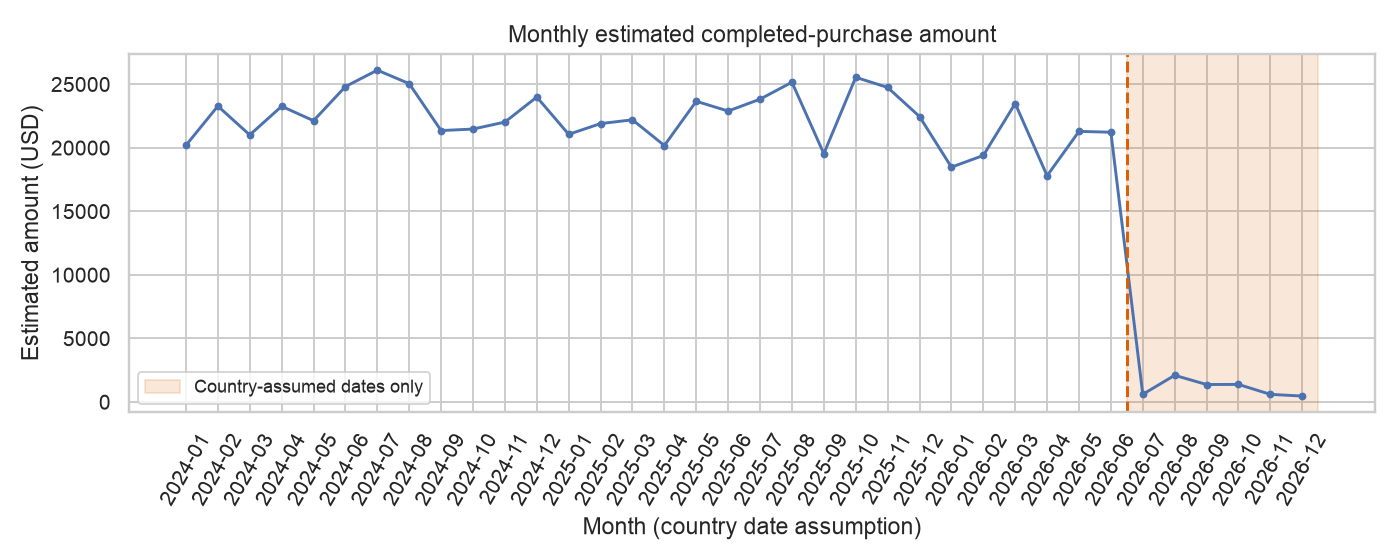

**결과 해석:** 국가 가정 기준 최고 월은 2024-07이며 추정 금액은 26,101.71 USD입니다. 전체 대상 금액은 675,801.92 USD입니다. 기준일 2026-12-05도 가정에 의해 도출된 데이터 기준일이며 실제 현재 시점의 매출 확정일을 뜻하지 않습니다. 출처 날짜 형식과 민감도 결과를 함께 확인한 뒤에만 월별 캠페인을 검토합니다.

,날짜 가정 영향
latest_unambiguous_date,2026-06-30
reference_extension_days,158
assumption_only_tail_rows,52
source_checked_on,2026-11-25
reference_after_source_check,True


In [17]:
display(report['monthly'].rename('추정 금액(USD)').to_frame())
display(Image(filename=str(report['output_dir']/'figures/06_line.png')))
peak = report['monthly'].idxmax()
explain(f'국가 가정 기준 최고 월은 {peak}이며 추정 금액은 {report["monthly"].max():,.2f} USD입니다. '
        f'전체 대상 금액은 {summary["estimated_amount_usd"]:,.2f} USD입니다. '
        f'기준일 {summary["reference_date"]}도 가정에 의해 도출된 데이터 기준일이며 실제 현재 시점의 매출 확정일을 뜻하지 않습니다. '
        '출처 날짜 형식과 민감도 결과를 함께 확인한 뒤에만 월별 캠페인을 검토합니다.')
display(pd.Series({k:summary[k] for k in ['latest_unambiguous_date','reference_extension_days','assumption_only_tail_rows','source_checked_on','reference_after_source_check']}).to_frame('날짜 가정 영향'))

## 17. RFM 점수와 고객 세분화
Recency는 기준일에서 마지막 유효 완료 구매일까지의 일수(작을수록 좋음), Frequency는 고유 주문 수, Monetary는 추정 할인 후 금액 합계입니다. 완료 구매가 없는 고객과 보류 거래는 별도로 집계합니다.

- R: Recency 역방향 백분위 순위에 `ceil(순위×4)` 적용.
- F: 구매 횟수 1·2·3·4회 이상을 각각 1·2·3·4점으로 매핑.
- M: Monetary 백분위 순위에 `ceil(순위×4)` 적용.
- 동점은 평균 순위로 동일 점수를 부여하므로 고객 ID 순서에 영향받지 않고, 그룹 크기가 정확히 25%일 필요도 없습니다.

아래 규칙은 위에서 먼저 만족한 그룹으로 배정합니다.

| 그룹 | 규칙 |
|---|---|
| VIP | R≥3, F≥3, M≥3 |
| Loyal | VIP 외 F≥3 |
| New | 앞선 그룹 외 R≥3이고 구매 1회 |
| At_Risk | 앞선 그룹 외 R≤2이고 구매 2회 이상 |
| Other | 나머지 |

R은 상대 순위이므로 ‘최근’이 최근 30일을 의미하지 않습니다. New는 관측 기간 내 최근의 단일 구매 고객이며 가입 정보가 없어 실제 신규 가입 고객으로 확정할 수 없습니다. At_Risk도 실제 이탈 여부를 검증한 분류가 아닙니다.

,customer_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,segment,imputed_orders,imputed_amount_usd
0,CUST00001,714,1,344.86,1,1,4,6,Other,0,0.0
1,CUST00002,392,2,256.0265,3,2,3,8,Other,0,0.0
2,CUST00003,246,5,1065.9175,4,4,4,12,VIP,0,0.0
3,CUST00004,32,3,402.0865,4,3,4,11,VIP,0,0.0
4,CUST00005,158,3,169.52,4,3,3,10,VIP,0,0.0
5,CUST00006,805,3,144.67,1,3,2,6,Loyal,0,0.0
6,CUST00007,491,2,405.157,2,2,4,8,At_Risk,0,0.0
7,CUST00008,460,3,317.0025,2,3,3,8,Loyal,0,0.0
8,CUST00009,446,3,192.639,2,3,3,8,Loyal,0,0.0
9,CUST00011,575,2,580.98,2,2,4,8,At_Risk,0,0.0


,customers,recency_mean,frequency_mean,monetary_mean,amount_usd,customer_pct,amount_pct
segment,,,,,,,
VIP,482,270.012448,3.599585,486.160589,234329.404,17.074035,34.674273
Loyal,339,500.920354,3.209440,297.669066,100909.81325,12.008502,14.931863
New,354,298.288136,1.000000,117.187846,41484.4975,12.539851,6.138559
At_Risk,400,642.635000,2.000000,235.604474,94241.78975,14.169323,13.945179
Other,1248,579.468750,1.380609,164.131741,204836.41325,44.208289,30.310126


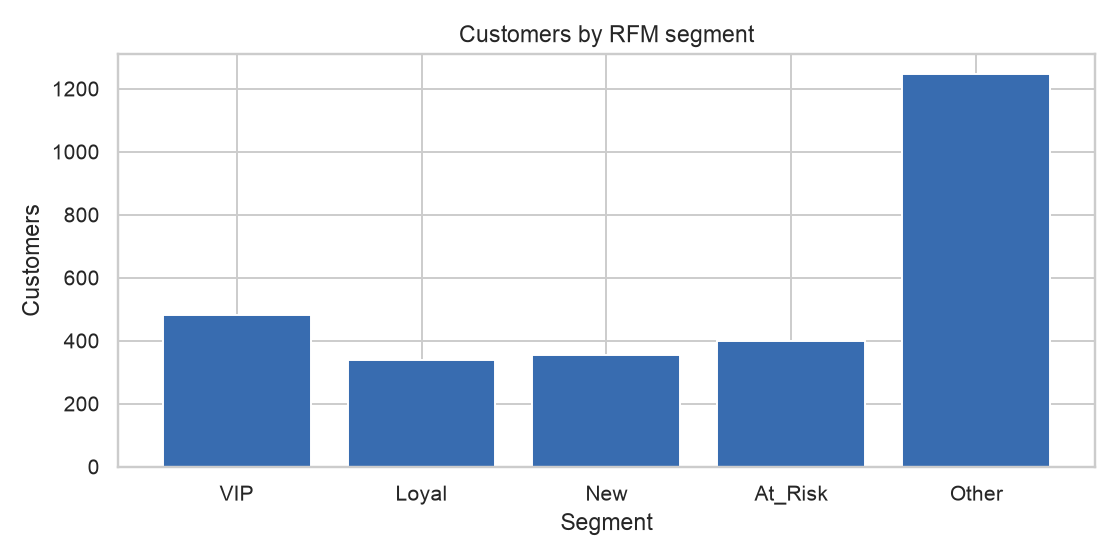

**결과 해석:** 기준일 2026-12-05, 고객 2,823명을 5개 그룹으로 나눴습니다. VIP는 482명이며 추정 금액의 34.67%를 차지합니다. 분석 대상이 아닌 고객 551명은 RFM에 포함되지 않아 전체 고객 기반과 구분해야 합니다.

In [18]:
display(rfm.head(10))
display(segments)
display(Image(filename=str(report['output_dir']/'figures/03_bar.png')))
explain(f'기준일 {summary["reference_date"]}, 고객 {len(rfm):,}명을 {rfm.segment.nunique()}개 그룹으로 나눴습니다. '
        f'VIP는 {int(segments.loc["VIP","customers"]):,}명이며 추정 금액의 {segments.loc["VIP","amount_pct"]:.2f}%를 차지합니다. '
        f'분석 대상이 아닌 고객 {summary["excluded_customers"]:,}명은 RFM에 포함되지 않아 전체 고객 기반과 구분해야 합니다.')

## 18. 날짜·금액 정의 민감도 분석
모든 시나리오는 **같은 5,700개 거래와 같은 금액**을 사용하며, 날짜가 모호한 거래만 재해석합니다. 국가 규칙 충돌로 보류된 거래는 대안에서도 복원하지 않습니다.

비교: 국가별 규칙 / 모든 모호한 날짜 월·일 / 모든 모호한 날짜 일·월 / 구분자별(`-` 월·일, `/` 일·월). 시나리오 전체 최대 날짜를 공통 기준일로 삼아 미래 거래로 인한 음수 Recency를 방지합니다. 이 기준일은 본 분석의 기준일과 다를 수 있습니다. 금액 월별 L1 차이는 월별 절대 변화의 합으로, 실제 매출 손실이 아닙니다.

추가로 같은 거래에서 Monetary를 할인 전 금액으로 계산해 그룹 변경률을 확인합니다. 할인율 추정의 오차를 정확히 측정한 결과가 아니라 금액 정의 변화에 대한 민감도입니다.

,scenario,shared_reference_date,transactions,customers,segment_changed,segment_changed_pct,recency_changed,monthly_amount_l1_change_usd,total_amount_usd
0,country_policy,2026-12-06,5700,2823,0,0.000000,0,0.0000,675801.91775
1,all_mdy,2026-12-06,5700,2823,82,2.904711,446,29965.5890,675801.91775
2,all_dmy,2026-12-06,5700,2823,17,0.602196,69,12990.9090,675801.91775
3,separator_policy,2026-12-06,5700,2823,47,1.664896,261,39176.4915,675801.91775


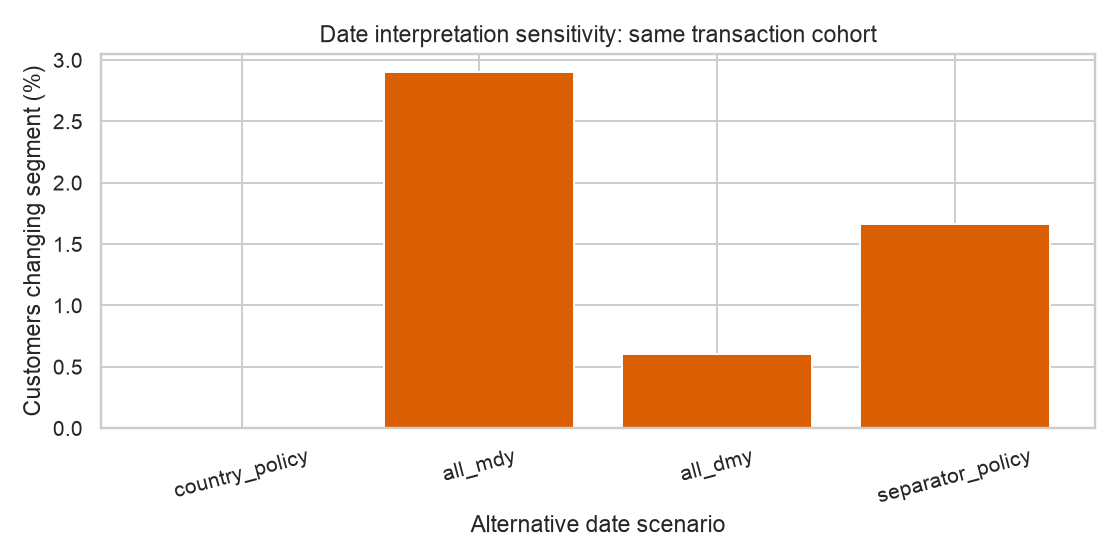

**결과 해석:** 날짜 해석에 따라 최대 2.90%의 고객군이 바뀝니다. 할인 전 금액으로 정의를 바꾸면 8명(0.28%)의 그룹이 바뀝니다. 관측된 변화가 작아도 가정이 옳음을 입증하지는 않으며, 보류 거래를 복구했을 때의 변화도 포함하지 않습니다.

In [19]:
display(report['date_sensitivity'])
display(Image(filename=str(report['output_dir']/'figures/07_sensitivity.png')))
worst = report['date_sensitivity'].segment_changed_pct.max()
explain(f'날짜 해석에 따라 최대 {worst:.2f}%의 고객군이 바뀝니다. '
        f'할인 전 금액으로 정의를 바꾸면 {summary["monetary_definition_segment_changed"]}명'
        f'({summary["monetary_definition_segment_changed_pct"]:.2f}%)의 그룹이 바뀝니다. '
        '관측된 변화가 작아도 가정이 옳음을 입증하지는 않으며, 보류 거래를 복구했을 때의 변화도 포함하지 않습니다.')

## 19. 비즈니스 제안: 근거·실행·검증
아래 제안은 합성 데이터에서 구성한 실무 가설입니다. 기대 효과는 측정할 목표이며, 이 데이터로 효과 크기나 인과성을 추정하지 않습니다.

In [20]:
vip = segments.loc['VIP']; risk = segments.loc['At_Risk']; new = segments.loc['New']
display(Markdown(f"""
### 제안 1. VIP 유지 실험
- **근거:** VIP {int(vip.customers):,}명({vip.customer_pct:.2f}%)이 추정 금액의 {vip.amount_pct:.2f}%를 차지합니다.
- **실행:** VIP를 대상으로 우선 상담·혜택을 시험하고, 무작위 대조군과 비교해 재구매율 유지·증대를 목표로 합니다.
- **검증:** 상품 원가·혜택 비용·후속 구매 이력이 필요합니다. 이익 개선이 없거나 대조군과 차이가 없으면 제안을 기각합니다.

### 제안 2. 이탈 위험 가설의 재구매 유도
- **근거:** At_Risk {int(risk.customers):,}명({risk.customer_pct:.2f}%)의 평균 Recency는 {risk.recency_mean:.1f}일입니다(가정 기준일의 연장 영향을 포함하며 실제 미구매 기간으로 확정하지 않음).
- **실행:** 이 그룹에 재입고 안내나 한정 혜택을 무작위 시험해 재구매 반응을 높이는 것을 목표로 합니다.
- **검증:** 마지막 구매일의 날짜 원본, 수신 동의·발송 이력·원가 데이터가 필요합니다. 날짜 재해석이나 자연 재구매로 설명되면 위험 분류 또는 캠페인 가설을 재검토합니다.

### 제안 3. 단일 구매 고객의 두 번째 구매 실험
- **근거:** New {int(new.customers):,}명({new.customer_pct:.2f}%)은 관측된 완료 주문이 1회이고 평균 추정 금액은 {new.monetary_mean:.2f} USD입니다.
- **실행:** 해당 고객에게 구매 상품과 관련된 안내를 시험해 두 번째 구매 전환율 증가를 목표로 합니다.
- **검증:** 가입일·이전 기간 구매·상품별 구매 주기와 후속 관측이 필요합니다. 실제 신규가 아니거나 재구매 주기가 길다면 대상 선정이 틀릴 수 있습니다.
"""))


### 제안 1. VIP 유지 실험
- **근거:** VIP 482명(17.07%)이 추정 금액의 34.67%를 차지합니다.
- **실행:** VIP를 대상으로 우선 상담·혜택을 시험하고, 무작위 대조군과 비교해 재구매율 유지·증대를 목표로 합니다.
- **검증:** 상품 원가·혜택 비용·후속 구매 이력이 필요합니다. 이익 개선이 없거나 대조군과 차이가 없으면 제안을 기각합니다.

### 제안 2. 이탈 위험 가설의 재구매 유도
- **근거:** At_Risk 400명(14.17%)의 평균 Recency는 642.6일입니다(가정 기준일의 연장 영향을 포함하며 실제 미구매 기간으로 확정하지 않음).
- **실행:** 이 그룹에 재입고 안내나 한정 혜택을 무작위 시험해 재구매 반응을 높이는 것을 목표로 합니다.
- **검증:** 마지막 구매일의 날짜 원본, 수신 동의·발송 이력·원가 데이터가 필요합니다. 날짜 재해석이나 자연 재구매로 설명되면 위험 분류 또는 캠페인 가설을 재검토합니다.

### 제안 3. 단일 구매 고객의 두 번째 구매 실험
- **근거:** New 354명(12.54%)은 관측된 완료 주문이 1회이고 평균 추정 금액은 117.19 USD입니다.
- **실행:** 해당 고객에게 구매 상품과 관련된 안내를 시험해 두 번째 구매 전환율 증가를 목표로 합니다.
- **검증:** 가입일·이전 기간 구매·상품별 구매 주기와 후속 관측이 필요합니다. 실제 신규가 아니거나 재구매 주기가 길다면 대상 선정이 틀릴 수 있습니다.


## 20. 재현·제출 점검
- 필수 6종 차트와 민감도 차트는 `output/analysis/figures/`에 저장됩니다. 제목·축 레이블은 차트 내 영어로 표기하고 해석은 한국어로 작성했습니다.
- 전체 데이터·분석 표·RFM 고객별 결과·집계·민감도 결과는 CSV 및 JSON으로 저장됩니다.
- 출처는 Kaggle의 AfaqKhan, 데이터 라이선스는 메타데이터 기준 CC0입니다. 저장소 소스 코드의 `LICENSE.txt`와 데이터 라이선스를 구분합니다.
- 분석은 NumPy·Pandas·Matplotlib·Seaborn으로 수행하며 머신러닝·전용 이미지 처리·자동 EDA 라이브러리를 직접 사용하지 않습니다.
- 국가별 날짜 가정, 합성 거래·합성 이미지, 할인율 대치·추정 금액, 관측 기간 제한을 결과와 함께 해석합니다.
- GitHub 업로드 전 변경 파일을 확인하고 프로젝트 README에서 실행 방법과 제출 링크를 확인하세요. 로컬 구현·검증과 원격 업로드 여부는 구분합니다.